# Where system dynamics is going in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/18-frontier.ipynb)

Much of the frontier of system dynamics is about letting the computer do more of the routine work: estimating parameters from data, hunting for flaws in a model, and searching for good policies. This notebook does a small version of each with plain Python loops: it fits the quality of work in the [Rework Cycle](https://waelrash1.github.io/loopbricks/#/m/reworkCycle) to noisy data, runs an automatic extreme conditions check over several molecules (among them [Reducing Backlog](https://waelrash1.github.io/loopbricks/#/m/reducingBacklog) and [Stock Management](https://waelrash1.github.io/loopbricks/#/m/stockmgmt)), and searches for the best ordering policy in Stock Management.

It goes with the [Where system dynamics is going module](https://waelrash1.github.io/loopbricks/#/learn/frontier) in the app.

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. Fitting a parameter to data

Projects run late in a predictable way. In the **Rework Cycle**, a team works through 1,000 tasks, but only a fraction (the `Quality`) is done right. The rest becomes undiscovered rework, which looks finished until it is found, some weeks later, and goes back on the pile. First see what quality does.

quality 0.95: at week 16 work to do   0.9, undiscovered rework   8.5, work done 990.5
quality 0.8: at week 16 work to do   5.3, undiscovered rework  48.7, work done 946.0
quality 0.6: at week 16 work to do  17.1, undiscovered rework 152.6, work done 830.3


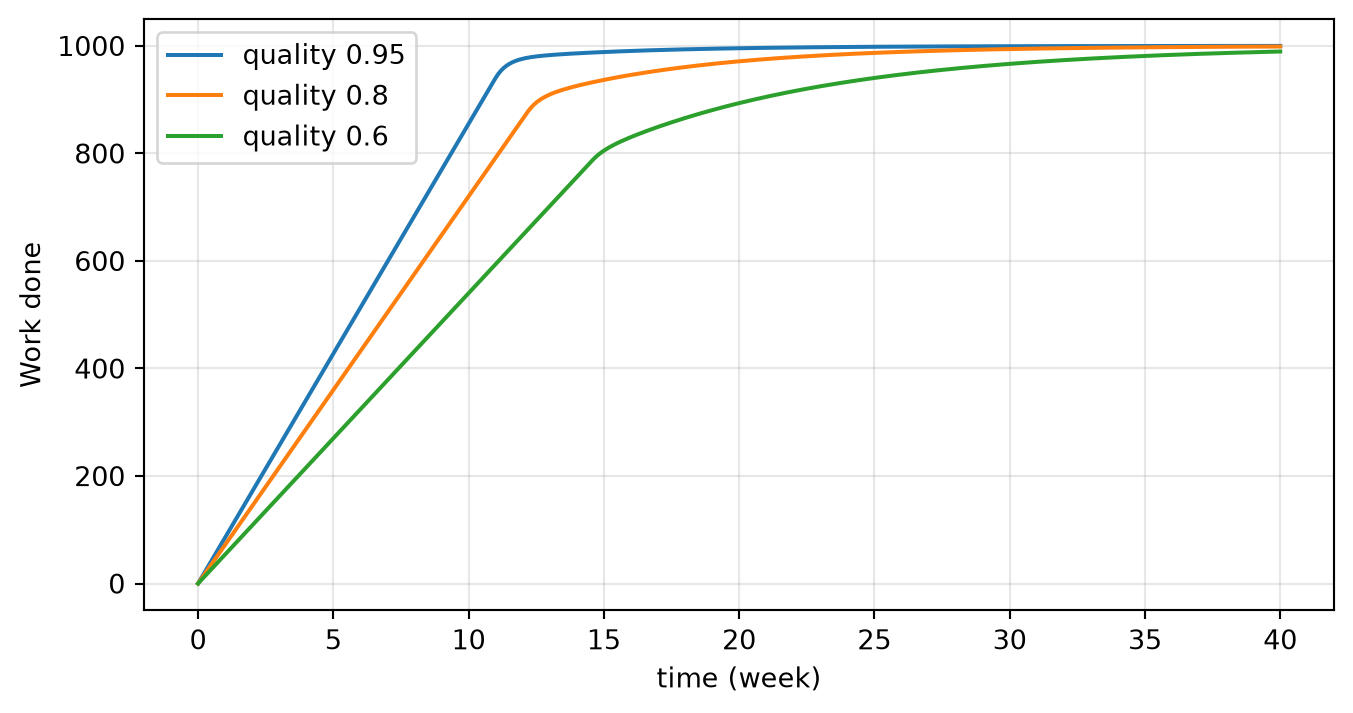

In [2]:
import numpy as np
rw = lb.molecule("reworkCycle")
fig, ax = plt.subplots(figsize=(8, 4))
for q in (0.95, 0.8, 0.6):
    run = rw.run(T=40, quality=q)
    run["Work done"].plot(ax=ax, label=f"quality {q}")
    print(f"quality {q}: at week 16 work to do {run.loc[16.0, 'Work to do']:5.1f}, "
          f"undiscovered rework {run.loc[16.0, 'Undiscovered rework']:5.1f}, work done {run.loc[16.0, 'Work done']:5.1f}")
ax.set_ylabel("Work done"); ax.legend(); ax.grid(alpha=0.3)

At week 16 the visible pile of work to do is small in every case (under 20 tasks). What differs is the hidden stock: with 60% quality, about 153 tasks of undiscovered rework are waiting to surface, and work done is only 830. A manager watching the visible pile would think the project was nearly finished. The lateness comes from the structure, not from bad luck.

In a real project you do not know the quality; you have a record of work done, with errors in it. **Calibration** finds the parameter value that makes the model fit that record best. Here we make a fake record from a run with quality 0.7, add random errors, and then pretend we do not know the 0.7. The search is the simplest one there is: try every value on a grid and keep the one with the smallest sum of squared errors.

best fitting quality: 0.69


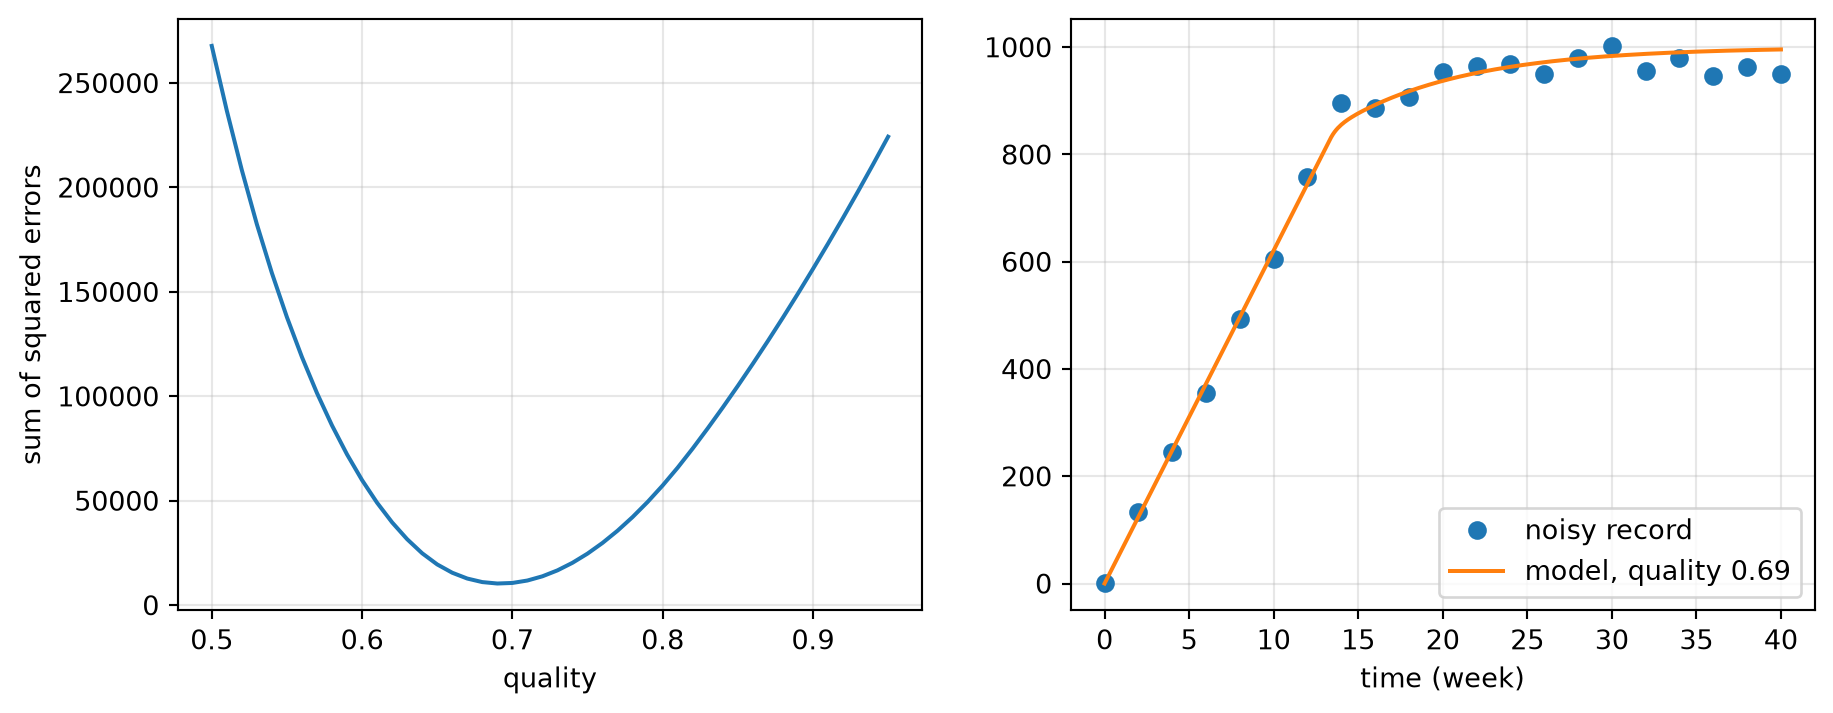

In [3]:
rng = np.random.default_rng(7)
weeks = np.arange(0, 41, 2.0)                      # a report every two weeks
truth = rw.run(T=40, quality=0.7).loc[weeks, "Work done"].values
observed = truth + rng.normal(0, 25, len(weeks))   # reporting errors of about 25 tasks

def fit_quality(data):
    grid = np.round(np.arange(0.5, 0.96, 0.01), 2)
    errors = [((rw.run(T=40, quality=q).loc[weeks, "Work done"].values - data) ** 2).sum() for q in grid]
    return grid[int(np.argmin(errors))], grid, errors

best, grid, errors = fit_quality(observed)
print("best fitting quality:", best)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(grid, errors); ax1.set_xlabel("quality"); ax1.set_ylabel("sum of squared errors"); ax1.grid(alpha=0.3)
ax2.plot(weeks, observed, "o", label="noisy record")
rw.run(T=40, quality=best)["Work done"].plot(ax=ax2, label=f"model, quality {best}")
ax2.legend(); ax2.grid(alpha=0.3)

The search lands on 0.69, within 0.01 of the true value, and the error curve has a single clear valley. With one parameter and a fast model, trying every value is perfectly good; with dozens of parameters, the same idea needs smarter search methods, and that is where much current work (including machine learning) comes in.

**Try it.** Make the reporting errors four times larger (a standard deviation of 100 tasks). Fit ten different noisy records (seeds 0 to 9) and look at the spread of the estimates. How sure can you be of the quality now?

<details><summary>Show a worked answer</summary>

The next cell does it. The estimates range from 0.65 to 0.78, with most between 0.67 and 0.72. They still centre near the true 0.7, but any single fit could be off by as much as 0.08, which in this model is the difference between a project that is slightly late and one with a long tail of rework. A fit always comes with uncertainty, and fitting many noisy records (or bootstrapping one) is a simple way to see how much.
</details>

In [4]:
estimates = []
for seed in range(10):
    noisy = truth + np.random.default_rng(seed).normal(0, 100, len(weeks))
    estimates.append(float(fit_quality(noisy)[0]))
print(estimates)

[0.71, 0.72, 0.72, 0.65, 0.68, 0.71, 0.78, 0.67, 0.68, 0.71]


## 2. Software that tests the model for you

Extreme conditions tests are tedious by hand, which is exactly why software should run them. Here is a small automatic checker. For each constant in a model, it runs the model with that constant at a tenth and at ten times its usual value, and looks for one specific impossibility: a stock that is **empty while flows are still taking from it**. (The stocks here are held at zero, so that is how a missing first-order control shows up.)

In [5]:
def drained_while_empty(model, run):
    """Stocks that sit at zero while their outflows are bigger than their inflows."""
    found = []
    for s in model.stocks:
        ins = [f["name"] for f in model.flows if f.get("to") == s["id"]]
        outs = [f["name"] for f in model.flows if f.get("from") == s["id"]]
        if not outs:
            continue
        net = run[ins].sum(axis=1) - run[outs].sum(axis=1)
        bad = (run[s["name"]] <= 1e-9) & (net < -1e-6)
        if bad.any():
            found.append(f"{s['name']} empty but still drained from t = {bad.idxmax()}")
    return found

def auto_test(key):
    model = lb.molecule(key)
    problems = []
    for name, value in model.params.items():
        for factor in (0.1, 10):
            for p in drained_while_empty(model, model.run(**{name: value * factor})):
                problems.append(f"{name} x {factor}: {p}")
    print(f"{key}: {'passes' if not problems else 'FAILS'}")
    for p in problems:
        print("   ", p)

for key in ("reducingBacklog", "doingWork", "protFlow", "backlogLevel", "stockmgmt"):
    auto_test(key)

reducingBacklog: FAILS
    workers x 10: Work to do empty but still drained from t = 3.0
    productivity x 10: Work to do empty but still drained from t = 3.0
doingWork: passes
protFlow: passes
backlogLevel: passes
stockmgmt: FAILS
    demand x 10: Inventory empty but still drained from t = 0.8


In a fraction of a second the checker runs every constant at both extremes in five molecules. It flags **Reducing Backlog**, whose work keeps being "done" after the backlog is empty when the team or its productivity is ten times larger. That one is a known teaching example. More interesting is **Stock Management**: with demand ten times higher (100 a week), sales carry on at 100 a week from an empty warehouse for several weeks. The molecule leaves out a limit on shipments because it is built to show the ordering decision, not the warehouse, but a model built on it for real use would need one. Doing Work, Level Protected by Flow and Backlog Protected by Level all pass, because each limits its outflow by what the stock holds.

A checker like this is crude: it tests one kind of failure, one constant at a time. Tools that explore a model's behaviour automatically, and link what they find back to the structure, are one of the open directions the module describes.

**Try it.** Look at the Stock Management failure in detail. When does inventory first hit zero, how long does it stay there, and what does it do in the end?

<details><summary>Show a worked answer</summary>

The next cell prints it. Orders jump to 245 a week, but acquisitions take time to catch up, so inventory runs out at week 0.8 and stays at zero until week 5.5, while sales of 100 a week continue as if nothing were wrong. Then the pipeline fills, inventory recovers, and it ends near its target of 100. A real warehouse would have lost or backlogged those sales: what is missing is a shipment rate like `MIN(Demand, Inventory / minimum shipping time)`, as in Level Protected by Flow.
</details>

In [6]:
high = lb.molecule("stockmgmt").run(demand=100)
empty = high.index[high["Inventory"] <= 1e-9]
print(f"inventory empty from week {empty[0]} to week {empty[-1]}; sales meanwhile: {high.loc[empty[0], 'Sales']:.0f} a week")
print(high.loc[[0, 0.8, 5, 60], ["Inventory", "Sales", "Acquisition", "Orders"]].round(1))

inventory empty from week 0.8 to week 5.5; sales meanwhile: 100 a week
             Inventory  Sales  Acquisition  Orders
time (week)                                       
0.0               60.0  100.0         10.0   245.0
0.8                0.0  100.0         38.0   218.0
5.0                0.0  100.0         98.0   128.1
60.0             100.0  100.0        100.0   100.0


## 3. Searching for a better policy

Once a model is trusted for a purpose, the computer can search through policies for you. Take Stock Management with a 12-week lead time (the *Long lead time* preset, which starts with too little on order). The manager controls two things: the **supply line weight** (how much of the shortfall in goods on order to count) and the **inventory adjustment time** (how quickly to correct the inventory gap). We score each policy by the average distance of inventory from its target of 100 over 100 weeks: lower is better.

In [7]:
import pandas as pd
sm = lb.molecule("stockmgmt")

def score(weight, adj_time):
    run = sm.run(T=100, preset="Long lead time", supply_line_weight=weight, inventory_adjustment_time=adj_time)
    return (run["Inventory"] - 100).abs().mean(), run["Orders"].max()

weights, times = (0, 0.25, 0.5, 0.75, 1), (2, 4, 8, 16)
results = {(w, t): score(w, t) for w in weights for t in times}
table = pd.DataFrame({f"weight {w}": [results[w, t][0] for t in times] for w in weights},
                     index=[f"adjust in {t} weeks" for t in times])
print("Average distance from target:")
print(table.round(2))
best = min(results, key=lambda k: results[k][0])
print(f"\nbest: weight {best[0]}, adjustment time {best[1]} (score {results[best][0]:.2f}, orders peak at {results[best][1]:.1f} a week)")

Average distance from target:
                    weight 0  weight 0.25  weight 0.5  weight 0.75  weight 1
adjust in 2 weeks       8.94         4.75        4.53         5.59      6.79
adjust in 4 weeks      10.55         7.61        6.99         7.60      8.79
adjust in 8 weeks      13.88        12.01       11.37        11.70     12.78
adjust in 16 weeks     19.98        19.14       18.98        19.61     20.67

best: weight 0.5, adjustment time 2 (score 4.53, orders peak at 45.0 a week)


The best policy in the grid corrects inventory fast (2 weeks) and counts half of the supply line gap, with an average miss of about 4.5 units. Counting none of the supply line is worst in every row. A weight of 1 is not best here either: in this run the supply line starts at half its desired level, and the full weight then raises inventory without overshoot but slowly. A score also hides costs it does not measure. The best policy gets there by ordering up to 45 a week, more than four times normal demand.

**Try it.** Suppose the supplier cannot take more than 30 orders a week. Search again, keeping only policies whose orders never go above 30. Which is best now, and how much worse is it?

<details><summary>Show a worked answer</summary>

The cell below filters the grid. No policy with a 2-week adjustment time stays under 30, so the best allowed one is a 4-week adjustment time with a weight of 0.5: an average miss of about 7.0 instead of 4.5, with orders peaking at 27.5. The answer to "what is the best policy" depends on what you count as a cost and what limits you respect, which is why policy search needs people to decide the goals, even when a computer does the searching.
</details>

In [8]:
allowed = {k: v for k, v in results.items() if v[1] <= 30}
best = min(allowed, key=lambda k: allowed[k][0])
print(f"best with orders at most 30: weight {best[0]}, adjustment time {best[1]}, "
      f"score {allowed[best][0]:.2f}, orders peak at {allowed[best][1]:.1f}")

best with orders at most 30: weight 0.5, adjustment time 4, score 6.99, orders peak at 27.5


## Where next

- Back in the app: the [Where system dynamics is going module](https://waelrash1.github.io/loopbricks/#/learn/frontier) discusses open questions in theory, tools, implementation and education. The [Machine learning and AI with system dynamics](https://waelrash1.github.io/loopbricks/#/methods/ml-ai) page goes further than the grid searches here.
- The tests automated in section 2 are introduced one by one in [Testing and building confidence](https://waelrash1.github.io/loopbricks/#/learn/testing); fitting and sensitivity have their own pages, the [Calibration lab](https://waelrash1.github.io/loopbricks/#/methods/calibration) and [Sensitivity lab](https://waelrash1.github.io/loopbricks/#/methods/sensitivity).
- The rework cycle also appears in [The modelling process](https://waelrash1.github.io/loopbricks/#/learn/process), and the ordering rule in [Oscillation](https://waelrash1.github.io/loopbricks/#/learn/oscillation).